# The week 36 model

**Incremental Predictive Value of Two Antenatal Visits for Recorded Low Birth Weight.** Kelvin Rwihimba, BSc Software Engineering, African Leadership University. Supervisor: Emmanuel Adjei.

This notebook walks through the second model in the repository. It predicts a recorded birth weight below 2.5 kg for pregnancies that have a visit between 33 and 36 weeks. It was built after the main study's single held out evaluation, with its own plan ([`week36_model/PROTOCOL.md`](../week36_model/PROTOCOL.md)) and its own sealed test set, which was opened once.

Every step here calls the tested code in `week36_model/`. The notebook adds no logic of its own. It never opens the test records: the test results below are read from the files written by that single evaluation.

Terms used:

* **ROC AUC**: how often a pregnancy that ended in low birth weight is ranked above one that did not. 0.5 is chance, 1 is perfect.
* **Sensitivity**: the share of low birth weight births the model flags.
* **Specificity**: the share of other births it does not flag.
* **PPV and NPV**: the share of flags that are real cases, and the share of non flags that are truly not cases.
* **Out of fold**: a prediction for a record made by a model that never saw that record during training.

In [1]:
import hashlib
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = Path.cwd().parent
FOLDER = ROOT / "week36_model"
sys.path.insert(0, str(FOLDER))

from antenatal.config import LIMITATION
from features import LANDMARKS, SETS, WINDOW, at_landmark, load_raw
from run_experiments import check_records, ids, out_of_fold

OUT, LOCKED, SEALED = FOLDER / "outputs", FOLDER / "locked", FOLDER / "sealed"
pd.set_option("display.precision", 3)

## 1. Three groups of records

The records were split once, before any model was fitted, into three lists kept in `week36_model/sealed/`:

* **development**: every model choice was made on these;
* **test**: sealed, opened once for the locked model;
* **quarantine**: the main study's held out partition, kept out so that this model never sees it.

The cell checks that no record sits in two lists, and that development code refuses sealed records.

In [2]:
lists = {name: set(ids(f"{name}_ids")) for name in ("development", "test", "quarantine")}
print({name: len(values) for name, values in lists.items()})
print("Overlaps:", len(lists["development"] & lists["test"]), len(lists["development"] & lists["quarantine"]),
      len(lists["test"] & lists["quarantine"]))
print("Test set evaluations logged:", len((SEALED / "test_access.log").read_text().strip().splitlines()))

raw = load_raw(ids("development_ids"))
check_records(raw.index)  # raises if any test or quarantine record is present
print(f"Development records loaded: {len(raw):,}")

{'development': 5257, 'test': 2121, 'quarantine': 783}
Overlaps: 0 0 0
Test set evaluations logged: 1
Development records loaded: 5,257


## 2. The moment of prediction

A prediction is made at a landmark week using the latest visit in a short window before it (its width is printed below). Only pregnancies with a visit in that window can be scored. Three landmarks were compared: 28, 32 and 36 weeks.

In [3]:
frames = {week: at_landmark(raw, week) for week in LANDMARKS}
reach = pd.DataFrame([{"landmark week": week, "records": len(f), "low birth weight": int(f["lbw"].sum()),
                       "share": f["lbw"].mean()} for week, f in frames.items()]).set_index("landmark week")
print(f"Window: the latest visit in the {WINDOW} weeks up to each landmark")
reach

Window: the latest visit in the 4 weeks up to each landmark


,records,low birth weight,share
landmark week,,,
28,2989,141,0.047
32,2811,108,0.038
36,2612,82,0.031


## 3. The predictor sets

The sets are nested, so any difference between them comes from the added information. Set D adds clinical flags and history fields.

In [4]:
for name, columns in SETS.items():
    print(f"Set {name} ({len(columns)} inputs): {', '.join(columns)}\n")

Set A (14 inputs): age, gravidity, prior_deliveries, height_cm, registration_weight, prior_caesarean, prior_hypertension_pregnancy, chronic_hypertension, diabetes, hiv, tuberculosis, sickle_cell, smoking, intimate_partner_violence

Set B (20 inputs): age, gravidity, prior_deliveries, height_cm, registration_weight, prior_caesarean, prior_hypertension_pregnancy, chronic_hypertension, diabetes, hiv, tuberculosis, sickle_cell, smoking, intimate_partner_violence, sbp, dbp, weight, ga, pulse, hb

Set C (26 inputs): age, gravidity, prior_deliveries, height_cm, registration_weight, prior_caesarean, prior_hypertension_pregnancy, chronic_hypertension, diabetes, hiv, tuberculosis, sickle_cell, smoking, intimate_partner_violence, sbp, dbp, weight, ga, pulse, hb, sbp_first, dbp_first, weight_first, ga_first, pulse_first, weight_gain_week

Set D (44 inputs): age, gravidity, prior_deliveries, height_cm, registration_weight, prior_caesarean, prior_hypertension_pregnancy, chronic_hypertension, diabete

## 4. Development results

Every set and method was compared at every landmark by grouped repeated cross validation on development records (`week36_model/outputs/development_results.csv`). The selection rule, fixed in advance in protocol Section 7, picks the landmark, then the model with the best specificity at 75 percent sensitivity, breaking ties towards fewer inputs and linear models. It chose logistic regression on set B at 36 weeks.

In [5]:
development = pd.read_csv(OUT / "development_results.csv")
logistic = development[development["method"] == "logistic"]
logistic.pivot(index="landmark", columns="set", values="roc_auc")

set,A,B,C,D
landmark,,,,
28,0.609,0.618,0.607,0.636
32,0.608,0.602,0.635,0.660
36,0.600,0.648,0.654,0.638


In [6]:
chosen = development.query("landmark == 36 and set == 'B' and method == 'logistic'").iloc[0]
print(f"Chosen: logistic regression, set B, week 36")
print(f"Development ROC AUC {chosen.roc_auc:.3f} ({chosen.roc_low:.3f} to {chosen.roc_high:.3f}), "
      f"{int(chosen.n):,} records with {int(chosen.events)} low birth weight births")
print(f"Specificity at 75 percent sensitivity: {chosen.specificity_at_75:.3f}")

Chosen: logistic regression, set B, week 36
Development ROC AUC 0.648 (0.583 to 0.709), 2,612 records with 82 low birth weight births
Specificity at 75 percent sensitivity: 0.508


## 5. Refit the chosen model here

This cell reruns the cross validation for the chosen configuration with the same code and seeds: 5 repeats of 5 folds, grouped by registration group, with the penalty tuned inside each training fold. It then checks that every out of fold prediction equals the stored one.

In [7]:
frame = frames[36]
start = time.perf_counter()
p = out_of_fold(frame, SETS["B"], "logistic")
stored = pd.read_parquet(OUT / "development_oof.parquet").query(
    "landmark == 36 and set == 'B' and method == 'logistic'").set_index("record_id")["p"]
gap = (pd.Series(p, index=frame.index) - stored.loc[frame.index]).abs().max()
print(f"Refitted in {time.perf_counter() - start:.1f} seconds")
print(f"Out of fold ROC AUC: {roc_auc_score(frame['lbw'], p):.3f}")
print(f"Largest difference from the stored predictions: {gap:.1e}")

Refitted in 3.6 seconds
Out of fold ROC AUC: 0.648
Largest difference from the stored predictions: 0.0e+00


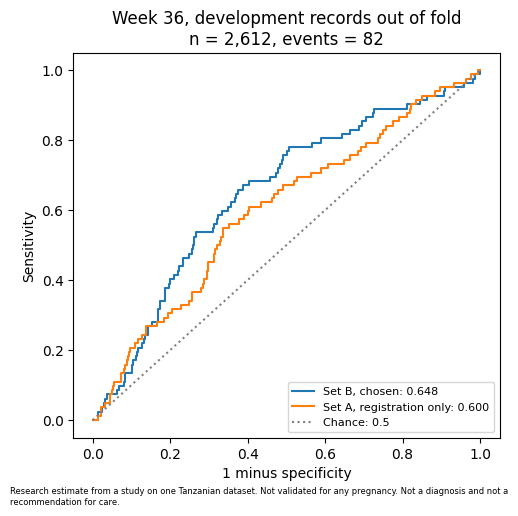

In [8]:
p_a = pd.read_parquet(OUT / "development_oof.parquet").query(
    "landmark == 36 and set == 'A' and method == 'logistic'").set_index("record_id")["p"].loc[frame.index]
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, scores in (("Set B, chosen", p), ("Set A, registration only", p_a)):
    fpr, tpr, _ = roc_curve(frame["lbw"], scores)
    ax.plot(fpr, tpr, label=f"{label}: {roc_auc_score(frame['lbw'], scores):.3f}")
ax.plot([0, 1], [0, 1], ls=":", c="grey", label="Chance: 0.5")
ax.set(xlabel="1 minus specificity", ylabel="Sensitivity",
       title=f"Week 36, development records out of fold\nn = {len(frame):,}, events = {int(frame['lbw'].sum())}")
ax.legend(loc="lower right", fontsize=8)
fig.text(0.01, -0.02, LIMITATION, fontsize=6, wrap=True)
plt.show()

## 6. The locked model

The chosen configuration was refitted on all development records at 36 weeks, saved with a checksum, and committed (commit 6dda03c) before the test set was opened. The cell checks the checksum and lists the coefficients.

The coefficients are on standardised inputs, so their sizes can be compared. They describe how the model weighs its inputs. They are not clinical explanations of low birth weight. Inputs ending in "missing" are indicators that a value was not recorded.

In [9]:
locked = json.loads((LOCKED / "locked.json").read_text())
path = LOCKED / "model_set_B.joblib"
assert hashlib.sha256(path.read_bytes()).hexdigest() == locked["models"]["B"]["sha256"]
print("Checksum matches locked.json")
print(f"Threshold: {locked['models']['B']['threshold']:.4f}")

model = joblib.load(path)
imputer = model.prepare_.named_steps["simpleimputer"]
names = SETS["B"] + [f"{SETS['B'][i]} missing" for i in imputer.indicator_.features_]
coefficients = pd.Series(model.model_.coef_[0], index=names, name="coefficient")
print(f"Penalty strength chosen by inner folds: C = {model.penalty_}")
coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).to_frame()

Checksum matches locked.json
Threshold: 0.0294
Penalty strength chosen by inner folds: C = 0.01


,coefficient
hb missing,0.125
registration_weight,-0.124
weight,-0.115
sbp,0.097
ga,-0.091
hb,-0.090
age,-0.075
height_cm,-0.066
intimate_partner_violence,-0.066
hiv,-0.054


## 7. The single test evaluation

The test set was opened once, on 7 November 2026, with the locked model and the same configuration on sets A and C for comparison. These are the files that evaluation wrote; nothing is recomputed.

In [10]:
test = pd.read_csv(OUT / "test_results.csv").set_index("set")
shown = pd.DataFrame({
    "ROC AUC (95% interval)": [f"{r.roc_auc:.3f} ({r.roc_auc_low:.3f} to {r.roc_auc_high:.3f})" for r in test.itertuples()],
    "Sensitivity": [f"{r.sensitivity:.3f} ({r.tp} of {r.tp + r.fn})" for r in test.itertuples()],
    "Specificity": test["specificity"].round(3).to_list(),
    "PPV": test["ppv"].round(3).to_list(),
    "NPV": test["npv"].round(3).to_list(),
}, index=test.index)
shown

,ROC AUC (95% interval),Sensitivity,Specificity,PPV,NPV
set,,,,,
A,0.685 (0.592 to 0.779),0.897 (26 of 29),0.275,0.037,0.989
B,0.706 (0.624 to 0.781),0.862 (25 of 29),0.508,0.051,0.992
C,0.692 (0.602 to 0.779),0.828 (24 of 29),0.482,0.047,0.989


In [11]:
comparisons = pd.read_csv(OUT / "test_comparisons.csv")
comparisons

,comparison,difference,low,high,p
0,"B over A, ROC AUC",0.021,-0.070,0.105,0.636
1,"B over A, PR AUC",-0.004,-0.048,0.033,0.762
2,"C over B, ROC AUC",-0.015,-0.056,0.028,0.450
3,"C over B, PR AUC",-0.007,-0.040,0.015,0.451
4,"C over A, ROC AUC",0.006,-0.097,0.107,0.917
5,"C over A, PR AUC",-0.011,-0.065,0.027,0.469


## 8. How to read the result

The cell below prints the three facts that must travel with the headline number. Each comes from the files above.

In [12]:
reach = json.loads((OUT / "test_reach.json").read_text())
b, a = test.loc["B"], test.loc["A"]
c_over_b = comparisons.set_index("comparison").loc["C over B, ROC AUC"]
b_over_a = comparisons.set_index("comparison").loc["B over A, ROC AUC"]
print(f"1. It sees only pregnancies with a visit at 33 to 36 weeks: {reach['at_landmark_records']} of "
      f"{reach['test_records']:,} test records. It found {int(b.tp)} of all {reach['test_events_all']} "
      f"low birth weight births among the test records; the rest had no visit in the window.")
print(f"2. Most of its separation comes from whom it sees: registration data alone (set A) reached "
      f"{a.roc_auc:.3f}; adding the late visit changed ROC AUC by {b_over_a.difference:+.3f} "
      f"({b_over_a.low:+.3f} to {b_over_a.high:+.3f}).")
print(f"3. The first visit adds nothing here either: C over B changed ROC AUC by {c_over_b.difference:+.3f} "
      f"({c_over_b.low:+.3f} to {c_over_b.high:+.3f}), repeating the main study's finding on records "
      f"sealed separately.")

1. It sees only pregnancies with a visit at 33 to 36 weeks: 975 of 2,121 test records. It found 25 of all 78 low birth weight births among the test records; the rest had no visit in the window.
2. Most of its separation comes from whom it sees: registration data alone (set A) reached 0.685; adding the late visit changed ROC AUC by +0.021 (-0.070 to +0.105).
3. The first visit adds nothing here either: C over B changed ROC AUC by -0.015 (-0.056 to +0.028), repeating the main study's finding on records sealed separately.


## 9. What this model is and is not

* It is internally developed and tested once on records from the same dataset. It has not been validated on any other population.
* It flags about half of the women it sees, so most flags are not low birth weight births.
* It cannot help a pregnancy that ends before 33 weeks.
* It is a research result, not a clinical tool, and it is not used by the web application.

The seven further analyses that tried to improve or combine the two models, all without changing a conclusion, are listed in [`docs/analyses_register.md`](../docs/analyses_register.md).